# 4. Modeling
We compare a baseline, logistic regression, a decision tree and random forest.
Each classifier is tested with all inputs and with L1-selected inputs.
Binary F1 is the main metric. The later holdout stays for Evaluation.

In [1]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import TimeSeriesSplit
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score
from preparation import fill_data, scale_data, encode_data

## Load the development data
We start from the clean, unscaled table so each validation fold can learn its
own preparation. The development period is the one defined in notebook 03.

In [2]:
train = pd.read_csv("../data/clean/train.csv", parse_dates=["purchase_date"])
train = train.sort_values(["purchase_date", "ID"]).set_index("ID")
target = "repeat_purchase_90d"

In [3]:
cut = train["purchase_date"].quantile(0.8).normalize()
gap = cut - pd.Timedelta(days=90)
dev = train.loc[train["purchase_date"] < gap].copy()

print("Development purchases:", len(dev))
print("Development ends:", dev["purchase_date"].max().date())
print("Holdout starts:", cut.date())

Development purchases: 5024
Development ends: 2023-03-18
Holdout starts: 2023-06-17


In [4]:
dev["purchase_year"] = dev["purchase_date"].dt.year
dev["purchase_month"] = dev["purchase_date"].dt.month.astype(str)
dev["purchase_weekday"] = dev["purchase_date"].dt.dayofweek.astype(str)

X = dev.drop(columns=["customer_id", "purchase_date", target])
y = dev[target]

## Define three temporal folds
Same-day purchases stay together. Each training period ends more than 90 days
before validation starts, so its labels would already be known. Customers may
appear in both periods because we also predict later purchases by existing customers.

In [5]:
dates = dev["purchase_date"].sort_values().unique()
cv = TimeSeriesSplit(n_splits=3)
splits = []
rows = []

for i, split in enumerate(cv.split(dates), 1):
    idx = split[1]
    start = pd.Timestamp(dates[idx[0]])
    end = pd.Timestamp(dates[idx[-1]])
    tr = dev.index[dev["purchase_date"] < start - pd.Timedelta(days=90)]
    va = dev.index[dev["purchase_date"].between(start, end)]
    splits.append((tr, va))
    rows.append([i, len(tr), len(va), dev.loc[tr, "purchase_date"].max(), start, end])

In [6]:
res = pd.DataFrame(rows, columns=["fold", "train rows", "validation rows",
                                  "last training date", "validation starts", "validation ends"])
res

,fold,train rows,validation rows,last training date,validation starts,validation ends
0,1,994,1349,2017-07-15,2017-10-14,2019-09-17
1,2,2362,1329,2019-06-18,2019-09-20,2021-07-26
2,3,3701,1147,2021-04-27,2021-07-27,2023-03-18


## Repeat the same evaluation for each model
The function below repeats one job: prepare a training fold, fit the model and
score its validation fold. Preparation uses the three steps already shown in
notebook 03. No validation rows contribute to fitted transformations.

With `selection=True`, L1 logistic regression first selects inputs within that
training fold. We use `C=0.1` and keep absolute coefficients above 0.000001.
The function is reused in the seven comparisons below.

In [7]:
def evaluate(model, selection=False):
    rows = []
    for i, (tr, va) in enumerate(splits, 1):
        X_train, X_valid, num, cat = fill_data(X.loc[tr], X.loc[va])
        X_train, X_valid = scale_data(X_train, X_valid, num)
        X_train, X_valid = encode_data(X_train, X_valid, cat)
        y_train = y.loc[tr]
        y_valid = y.loc[va]

        if selection:
            select = LogisticRegression(penalty="l1", solver="liblinear", C=0.1,
                                         max_iter=2000, random_state=42)
            select.fit(X_train, y_train)
            keep = np.abs(select.coef_[0]) > 0.000001
            cols = X_train.columns[keep]
            X_train = X_train[cols]
            X_valid = X_valid[cols]

        model.fit(X_train, y_train)
        pred = model.predict(X_valid)
        f1 = f1_score(y_valid, pred)
        rows.append([i, X_train.shape[1], f1])

    res = pd.DataFrame(rows, columns=["fold", "n_features", "F1"])
    return res

## Majority-class baseline
The baseline predicts whichever class is most frequent in that training fold.
We keep its three scores as a reference for the classifiers.

In [8]:
scores = []
model = DummyClassifier(strategy="most_frequent")
res = evaluate(model)
res["model"] = "Baseline"
res["features"] = "All"
scores.append(res)
res.round(4)

,fold,n_features,F1,model,features
0,1,143,0.7128,Baseline,All
1,2,192,0.7233,Baseline,All
2,3,237,0.6770,Baseline,All


## Logistic regression
We use `C=1` and compare all inputs with the L1 subset. Model settings remain
fixed across the three folds; this homework does not tune hyperparameters.

In [9]:
model = LogisticRegression(C=1, solver="liblinear", max_iter=2000, random_state=42)
res = evaluate(model)
res["model"] = "Logistic regression"
res["features"] = "All"
scores.append(res)
res.round(4)

,fold,n_features,F1,model,features
0,1,143,0.6650,Logistic regression,All
1,2,192,0.6600,Logistic regression,All
2,3,237,0.6938,Logistic regression,All


With L1 selection:

In [10]:
res = evaluate(model, selection=True)
res["model"] = "Logistic regression"
res["features"] = "L1"
scores.append(res)
res.round(4)

,fold,n_features,F1,model,features
0,1,20,0.7539,Logistic regression,L1
1,2,32,0.7123,Logistic regression,L1
2,3,41,0.7300,Logistic regression,L1


## Decision tree
We limit depth to 5 and require at least 20 purchases per leaf to avoid very
specific rules based on few observations.

In [11]:
model = DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, random_state=42)
res = evaluate(model)
res["model"] = "Decision tree"
res["features"] = "All"
scores.append(res)
res.round(4)

,fold,n_features,F1,model,features
0,1,143,0.7416,Decision tree,All
1,2,192,0.7017,Decision tree,All
2,3,237,0.7110,Decision tree,All


With L1 selection:

In [12]:
res = evaluate(model, selection=True)
res["model"] = "Decision tree"
res["features"] = "L1"
scores.append(res)
res.round(4)

,fold,n_features,F1,model,features
0,1,20,0.7180,Decision tree,L1
1,2,32,0.6880,Decision tree,L1
2,3,41,0.7246,Decision tree,L1


## Random forest
We use 200 trees and at least 5 purchases per leaf. The random seed is fixed.

In [13]:
model = RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                                random_state=42, n_jobs=2)
res = evaluate(model)
res["model"] = "Random forest"
res["features"] = "All"
scores.append(res)
res.round(4)

,fold,n_features,F1,model,features
0,1,143,0.7440,Random forest,All
1,2,192,0.7308,Random forest,All
2,3,237,0.7356,Random forest,All


With L1 selection:

In [14]:
res = evaluate(model, selection=True)
res["model"] = "Random forest"
res["features"] = "L1"
scores.append(res)
res.round(4)

,fold,n_features,F1,model,features
0,1,20,0.7482,Random forest,L1
1,2,32,0.7291,Random forest,L1
2,3,41,0.7379,Random forest,L1


## Compare the results
We compare mean F1 across the same three folds. The standard deviation
describes their variation; it is not a confidence interval.

In [15]:
scores = pd.concat(scores, ignore_index=True)
summary = scores.groupby(["model", "features"])["F1"].agg(["mean", "std"])
summary = summary.reset_index().sort_values("mean", ascending=False)
summary.round(4)

,model,features,mean,std
6,Random forest,L1,0.7384,0.0096
5,Random forest,All,0.7368,0.0067
4,Logistic regression,L1,0.7321,0.0209
1,Decision tree,All,0.7181,0.0209
2,Decision tree,L1,0.7102,0.0195
0,Baseline,All,0.7044,0.0243
3,Logistic regression,All,0.6729,0.0183


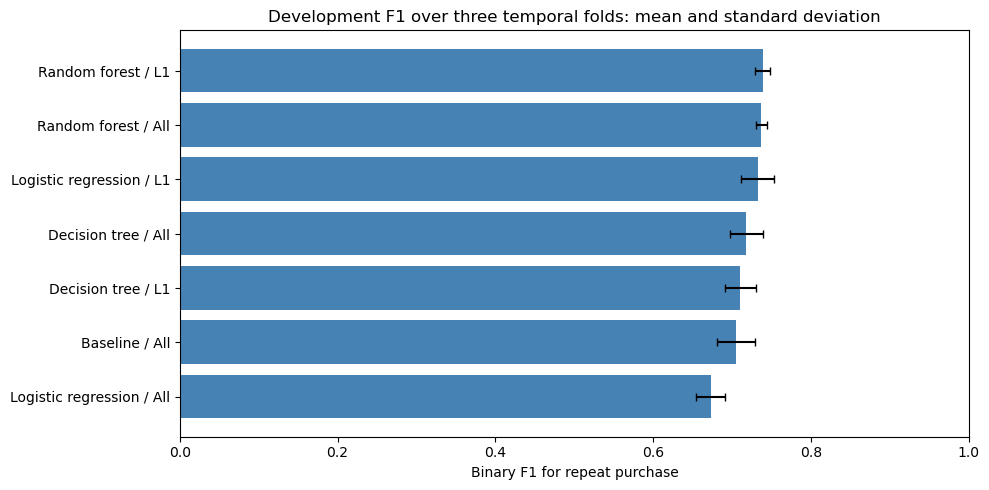

In [16]:
res = summary.sort_values("mean")
labels = res["model"] + " / " + res["features"]
plt.figure(figsize=(10, 5))
plt.barh(labels, res["mean"], xerr=res["std"], color="steelblue", capsize=3)
plt.title("Development F1 over three temporal folds: mean and standard deviation")
plt.xlabel("Binary F1 for repeat purchase")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

Random forest with L1 has the largest mean F1: **0.7384**, against **0.7044**
for the baseline. Forest with all inputs scores 0.7368. The 0.0016 advantage
is small and does not establish a reliable improvement, but L1 gives a smaller
input set. We choose forest + L1 using this development comparison.

## Select inputs on full development
We now use the matrix from notebook 03, fitted on all 5,024 development
purchases. L1 is fitted again on those purchases before the final development model.

In [17]:
train = pd.read_csv("../data/prepared/train.csv", index_col="ID")
X_train = train.drop(columns=target)
y_train = train[target]

In [18]:
select = LogisticRegression(penalty="l1", solver="liblinear", C=0.1,
                             max_iter=2000, random_state=42)
select.fit(X_train, y_train)
keep = np.abs(select.coef_[0]) > 0.000001
cols = X_train.columns[keep].tolist()
print("Selected inputs:", len(cols), "of", X_train.shape[1])

Selected inputs: 54 of 276


In [19]:
res = pd.Series(select.coef_[0], index=X_train.columns, name="coefficient")
res = res.loc[cols]
res = res.loc[res.abs().sort_values(ascending=False).index]
res.head(15).round(3)

purchase_count_365d                                            1.210
island_Missing                                                 0.613
purchase_count_90d                                             0.512
country_or_region_Country CT10: Land of The Final Version      0.391
purchase_month_9                                               0.359
purchase_month_12                                             -0.272
purchase_month_11                                             -0.269
purchase_weekday_0                                             0.265
purchase_month_3                                              -0.222
prior_max_purchase_value                                       0.218
municipality_Municipality MU9: Council of Last Minute Edits    0.215
purchase_month_4                                              -0.211
spend_90d                                                      0.205
Total Desc_ Linha                                              0.203
postal_area_infrequent_sklearn    

L1 retains **54 of 276 inputs**. These are screening coefficients, not causal
effects or forest importance scores. `random_noise` passes the fixed rule;
that does not prove stable signal. Its ablation remains for the final project.

## Fit the selected forest
We keep the settings used in the comparison. The later holdout is assessed
in the next notebook and is not used to change this choice or its threshold.

In [20]:
model = RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                                random_state=42, n_jobs=2)
model.fit(X_train[cols], y_train)

RandomForestClassifier(min_samples_leaf=5, n_estimators=200, n_jobs=2,
                       random_state=42)

## Save the model and results
Evaluation loads this forest and the selected-column CSV. Deployment rebuilds
the same forest + L1 method on all eligible labelled purchases.

In [21]:
os.makedirs("../results", exist_ok=True)
scores.to_csv("../results/cv_results.csv", index=False)
summary.to_csv("../results/cv_summary.csv", index=False)
pd.Series(cols, name="feature").to_csv("../results/selected_features.csv", index=False)
joblib.dump(model, "../results/development_model.joblib")

['../results/development_model.joblib']

Next: [Evaluation](05_Evaluation.ipynb).